# 多变量线性回归

## 问题描述

你将使用房价预测这一引入示例。训练数据集包含三个样本，每个样本有四个特征（面积、卧室数、楼层数和房龄），如下表所示。请注意，与之前的实验不同，面积的单位是平方英尺，而不是千平方英尺。这会引发一个问题，你将在后面解决这个问题

| 面积（平方英尺） | 卧室数量  | 楼层数 | 房龄 | 价格（千美元）  |   
| ----------------| ------------------- |----------------- |--------------|-------------- |  
| 2104            | 5                   | 1                | 45           | 460           |  
| 1416            | 3                   | 2                | 40           | 232           |  
| 852             | 2                   | 1                | 35           | 178           |  

你将使用这些值构建线性回归模型，以便预测其他房屋的价格。例如，一栋面积为 1200 平方英尺、有 3 间卧室、1 层、房龄为 40 年的房屋。  


In [32]:
import copy, math
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=2)  # 降低 NumPy 数组的显示精度

# 创建训练实例
x_train = np.array([[2104, 5, 1, 45], [1416, 3, 2, 40], [852, 2, 1, 35]])
y_train = np.array([460, 232, 178])

## 包含样本的矩阵 X
当有m个训练样本时候，X的维度为(m,n)，其中n为特征的数量，m为样本的数量

$$\mathbf{X} = 
\begin{pmatrix}
 x^{(0)}_0 & x^{(0)}_1 & \cdots & x^{(0)}_{n-1} \\ 
 x^{(1)}_0 & x^{(1)}_1 & \cdots & x^{(1)}_{n-1} \\
 \cdots \\
 x^{(m-1)}_0 & x^{(m-1)}_1 & \cdots & x^{(m-1)}_{n-1} 
\end{pmatrix}
$$
符号：
- $\mathbf{x}^{(i)}$ 是包含样本 i 的向量。$\mathbf{x}^{(i)}$ $ = (x^{(i)}_0, x^{(i)}_1, \cdots,x^{(i)}_{n-1})$
- $x^{(i)}_j$ 是样本 i 中的元素 j。括号中的上标表示样本编号，下标则表示元素。  


## 参数向量 w, b

* $\mathbf{w}$ 是一个包含 $n$ 个元素的向量。
  - 每个元素包含与一个特征关联的参数。
  - 在我们的数据集中，n 为 4。
  - 在示意图中，我们将其画成列向量

$$\mathbf{w} = \begin{pmatrix}
w_0 \\ 
w_1 \\
\cdots\\
w_{n-1}
\end{pmatrix}
$$
* $b$ 是一个标量参数。  

In [33]:
b_init = 785.1811367994083
w_init = np.array([ 0.39133535, 18.75376741, -53.36032453, -26.42131618])
print(f"w_init shape: {w_init.shape}, b_init type: {type(b_init)}")

w_init shape: (4,), b_init type: <class 'float'>


## 多变量模型预测
$$f_{w,b} = w_0 x_0 + w_1 x_1 + \cdots + w_{n-1} x_{n-1} + b$$

In [34]:
def prefict_single_loop(x, w, b):
    """
    使用线性回归进行单次预测

    参数：
    x: 形状为 (n,) 的多特征样本
    w: 形状为 (n,) 的参数向量
    b: 模型参数

    返回：
    p: 预测值
    """
    return np.dot(x, w) + b



In [35]:
# 从训练数据中获取一行
x_vec = x_train[0, :]
print(f"x_vec shape: {x_vec.shape}, w_init shape: {w_init.shape}, b_init type: {type(b_init)}")
# 进行预测
p = prefict_single_loop(x_vec, w_init, b_init)
print(f"p = {p}")

x_vec shape: (4,), w_init shape: (4,), b_init type: <class 'float'>
p = 459.9999976194083


## 计算多变量代价
$$J_{w,b} = \frac{1}{2m} \sum_{i=1}^m (f_{w,b}(\mathbf{x}^{(i)}) - y^{(i)})^2$$

和之前不同，$w$ 和 $x^{(i)}$ 都是向量，所以我们需要使用向量化的方法来计算代价函数

In [36]:
def compute_cost(x, y, w, b):
    """
    计算代价
    """
    m = x.shape[0]
    cost = 0.0
    for i in range(m):
        f_wb = np.dot(x[i], w) + b
        cost += (f_wb - y[i]) ** 2
    return cost / (2 * m)

In [37]:
# 使用预先选定的最优参数计算并显示代价
cost = compute_cost(x_train, y_train, w_init, b_init)
print(f"cost = {cost}")

cost = 1.5578904428966628e-12


## 多变量梯度下降
多变量梯度下降：

$$\begin{align*} \text{repeat}&\text{ until convergence:} \; \lbrace \newline\;
& w_j = w_j -  \alpha \frac{\partial J(\mathbf{w},b)}{\partial w_j} \tag{5}  \; & \text{for j = 0..n-1}\newline
&b\ \ = b -  \alpha \frac{\partial J(\mathbf{w},b)}{\partial b}  \newline \rbrace
\end{align*}$$

其中，n 是特征数量，参数 $w_j$、$b$ 同时更新，并且  

$$
\begin{align}
\frac{\partial J(\mathbf{w},b)}{\partial w_j}  &= \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - y^{(i)})x_{j}^{(i)} \tag{6}  \\
\frac{\partial J(\mathbf{w},b)}{\partial b}  &= \frac{1}{m} \sum\limits_{i = 0}^{m-1} (f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - y^{(i)}) \tag{7}
\end{align}
$$
* m 是数据集中的训练样本数量

    
*  $f_{\mathbf{w},b}(\mathbf{x}^{(i)})$ 是模型的预测值，而 $y^{(i)}$ 是目标值

本节暂不做特征缩放。面积特征的数值达到上千，学习率 `0.1` 会导致梯度下降发散，出现溢出警告和 `nan`；下面使用 `5e-7`。运行 1000 次后代价应下降，但尚未完全收敛。

修改函数定义后，请从头运行所有代码单元格，确保内核使用最新定义；`gradient_descent` 应返回 `w, b, J_history`，否则最后的解包赋值会报 `TypeError`。


In [38]:
def compute_gradient(X, y, w, b):
    """
    计算线性回归的梯度
    返回：
        dj_dw : 代价相对于参数 w 的梯度
        dj_db  : 代价相对于参数 b 的梯度
    """
    m, n = X.shape
    dj_dw = np.zeros((n,))
    dj_db = 0.0

    for i in range(m):
        err = (np.dot(X[i], w) + b) - y[i]
        for j in range(n):
            dj_dw[j] += err * X[i, j]
        dj_db += err

    dj_dw = dj_dw / m
    dj_db = dj_db / m

    return dj_dw, dj_db

In [39]:
# 计算并显示梯度
tmp_dj_dw, tmp_dj_db = compute_gradient(x_train, y_train, w_init, b_init)
print(f"tmp_dj_dw = {tmp_dj_dw}, tmp_dj_db = {tmp_dj_db}")

tmp_dj_dw = [-2.73e-03 -6.27e-06 -2.22e-06 -6.92e-05], tmp_dj_db = -1.6739251501955248e-06


In [40]:
def gradient_descent(x, y, w_in, b_in, alpha, num_iters, cost_function, gradient_function):
    """
    执行批量梯度下降来学习参数

    参数：
    x: 形状为 (m, n) 的训练数据
    y: 形状为 (m,) 的目标值
    w_in: 形状为 (n,) 的参数向量
    b_in: 参数 b
    alpha: 学习率
    num_iters: 迭代次数
    cost_function: 代价函数
    
    返回：
    w_out: 学习后的参数向量
    b_out: 学习后的参数 b
    """
    w = copy.deepcopy(w_in)  # 避免在函数内修改全局 w
    b = b_in

    J_history = [] # 用于存储每次迭代后的 J 和 w 值的数组，主要用于后续绘图

    for i in range(num_iters):
        dj_dw, dj_db = gradient_function(x, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        # 保存每次迭代的代价 J
        if i < 100000:  # 只保存前 100000 次迭代的结果，以节省内存
            J_history.append(cost_function(x, y, w, b))

        if i % math.ceil(num_iters / 10) == 0:
            print(f"Iteration {i}: Cost {J_history[-1]:.4f}   ")

    return w, b, J_history


In [41]:
# 初始化参数
initial_w = np.zeros_like(w_init)
initial_b = 0.0
# 设置学习率和迭代次数
alpha = 5e-7 # 数值较大，所以学习率设置的小一点
num_iters = 1000
# 执行梯度下降
w_out, b_out, J_history = gradient_descent(x_train, y_train, initial_w, initial_b, alpha, num_iters, compute_cost, compute_gradient)
print(f"Final w: {w_out} \n Final b: {b_out}")
m, _ = x_train.shape
for i in range(m):
    print(f"Prediction: {np.dot(x_train[i], w_out) + b_out}, Target value: {y_train[i]}")


Iteration 0: Cost 2529.4630   
Iteration 100: Cost 695.9903   
Iteration 200: Cost 694.9207   
Iteration 300: Cost 693.8604   
Iteration 400: Cost 692.8094   
Iteration 500: Cost 691.7676   
Iteration 600: Cost 690.7349   
Iteration 700: Cost 689.7112   
Iteration 800: Cost 688.6965   
Iteration 900: Cost 687.6906   
Final w: [ 0.2   0.   -0.01 -0.07] 
 Final b: -0.002235407530932535
Prediction: 426.18530497189204, Target value: 460
Prediction: 286.1674720078562, Target value: 232
Prediction: 171.46763087132317, Target value: 178


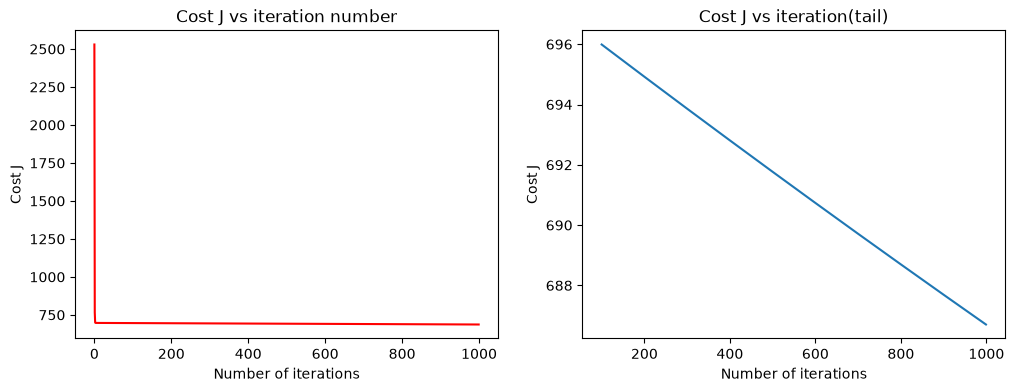

In [42]:
# 绘制代价随迭代次数变化的曲线
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
ax1.plot(J_history, 'r')
ax2.plot(100 + np.arange(len(J_history[100:])), J_history[100:])
ax1.set_title("Cost J vs iteration number")
ax2.set_title("Cost J vs iteration(tail)")
ax1.set_xlabel("Number of iterations")
ax1.set_ylabel("Cost J")
ax2.set_xlabel("Number of iterations")
ax2.set_ylabel("Cost J")
plt.show()


左图很奇怪，为什么是这样的？
刚开始，代价下降的非常快，然后逐渐变慢，最后几乎不再变化。但是，它收敛了吗？
并没有，右图放大来看仍然在下降，也就是没有收敛，为什么呢？

## 特征缩放
观察一下几个特征，我们发现不同特征的范围差距很大，这会导致需要迭代很多次才能收敛，甚至可能梯度下降发散。因此，我们需要对特征进行缩放，使其范围大致相同。最常用的方法是标准化（standardization）和归一化（normalization）。

代价等高线  
理解特征缩放的另一种方式是观察代价等高线。当特征尺度不匹配时，等高线图中代价相对于参数的图形是不对称的。 
当特征经过标准化后，代价等高线要对称得多。结果是，在梯度下降过程中进行参数更新时，每个参数都能取得相当的进展。 


### 标准化
$$ x_j^{(i)} = \frac{x_j^{(i)} - \mu_j}{\sigma_j} \tag{8}$$

### 归一化
$$ x_j^{(i)} = \frac{x_j^{(i)} - \min_j(x)}{\max_j(x) - \min_j(x)} \tag{9}$$

In [43]:
def zscore_normalize_features(X):
    """
    计算按列进行 z-score 标准化后的 X
    
    返回：
        X_norm: 形状为 (m, n) 的标准化后的 X
        mu: 形状为 (n,) 的均值向量
        sigma: 形状为 (n,) 的标准差向量
    """
    # 求每个特征的均值
    mu = np.mean(X, axis=0)
    # 求每个特征的标准差
    sigma = np.std(X, axis=0)
    X_norm = (X - mu) / sigma

    return X_norm, mu, sigma

### 标准化变换过程

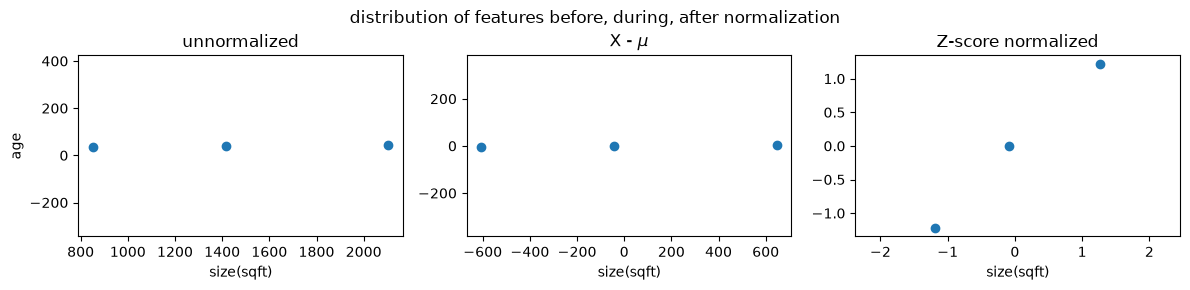

In [ ]:
x_features = ['size(sqft)','bedrooms','floors','age']

mu     = np.mean(x_train,axis=0)   
sigma  = np.std(x_train,axis=0) 
X_mean = (x_train - mu)
X_norm = (x_train - mu)/sigma      

fig,ax=plt.subplots(1, 3, figsize=(12, 3))
ax[0].scatter(x_train[:,0], x_train[:,3])
ax[0].set_xlabel(x_features[0]); ax[0].set_ylabel(x_features[3]);
ax[0].set_title("unnormalized")
ax[0].axis('equal')

ax[1].scatter(X_mean[:,0], X_mean[:,3])
ax[1].set_xlabel(x_features[0]); ax[0].set_ylabel(x_features[3]);
ax[1].set_title(r"X - $\mu$")
ax[1].axis('equal')

ax[2].scatter(X_norm[:,0], X_norm[:,3])
ax[2].set_xlabel(x_features[0]); ax[0].set_ylabel(x_features[3]);
ax[2].set_title(r"Z-score normalized")
ax[2].axis('equal')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
fig.suptitle("distribution of features before, during, after normalization")
plt.show()

Iteration 0: Cost 37840.4552   
Iteration 100: Cost 0.0000   
Iteration 200: Cost 0.0000   
Iteration 300: Cost 0.0000   
Iteration 400: Cost 0.0000   
Iteration 500: Cost 0.0000   
Iteration 600: Cost 0.0000   
Iteration 700: Cost 0.0000   
Iteration 800: Cost 0.0000   
Iteration 900: Cost 0.0000   
Final w: [ 38.05  41.54 -30.99  36.34] 
 Final b: 289.9999999999998
Prediction: 459.9999999999998, Target value: 460
Prediction: 231.99999999999977, Target value: 232
Prediction: 177.99999999999974, Target value: 178


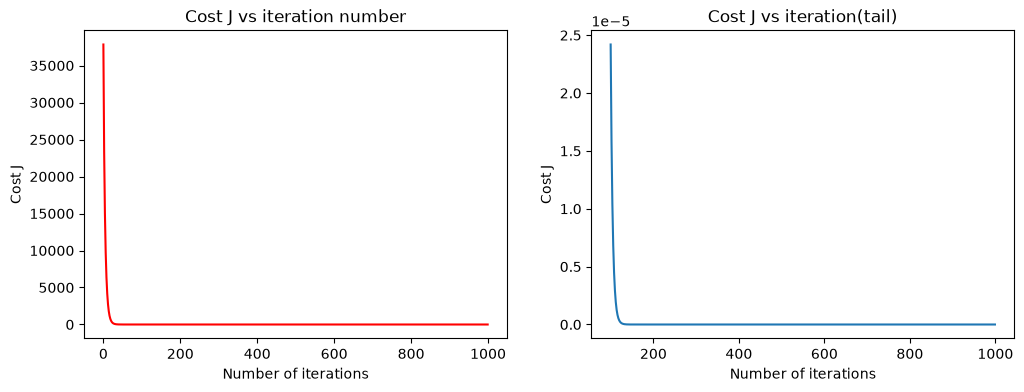

In [46]:
# 现在重新运行梯度算法，记得修改一下学习率
alpha = 1e-1
num_iters = 1000
w_out, b_out, J_history = gradient_descent(X_norm, y_train, initial_w, initial_b, alpha, num_iters, compute_cost, compute_gradient)
print(f"Final w: {w_out} \n Final b: {b_out}")
m, _ = x_train.shape
for i in range(m):
    print(f"Prediction: {np.dot(X_norm[i], w_out) + b_out}, Target value: {y_train[i]}")

# 绘制代价随迭代次数变化的曲线
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
ax1.plot(J_history, 'r')
ax2.plot(100 + np.arange(len(J_history[100:])), J_history[100:])
ax1.set_title("Cost J vs iteration number")
ax2.set_title("Cost J vs iteration(tail)")
ax1.set_xlabel("Number of iterations")
ax1.set_ylabel("Cost J")
ax2.set_xlabel("Number of iterations")
ax2.set_ylabel("Cost J")
plt.show()
